# Project T.H.A.N.O.S.: Master Research Pipeline (NMA Impact Scholars)
**Two-sided Hand-pose Adaptation with Non-negative and Orthogonal Structure**  
*Topological Hand Alignment via Neuromotor Orthogonal Subspaces*

**Team:** Andres Santiago Martinez Hernandez, Naveen Kumar Subramani, Wilbert Tan, Youssef Ibraheem  
**Partner Benchmark:** Meta Reality Labs `emg2pose`

---

Hey guys! in order to give some guidance and understanding of the project as a whole (along with polishing the topics myself) i've created this notebook.

It operates with the absolute basics and a tiny sample of the dataset. Your respective work will be to lead on each section to go beyond this code and hopefuly come up with something truly awesome

HW is on it's way! so let's make sure we can test it along the way once we have some nice model reductions and generalizations

-Santi
### Roadmap
1. **Module 0 (Setup & DSP):** Environment setup, `h5py` structured data loader, EEG-inspired channel artifact rejection, and 4-stage sEMG envelope pipeline (20–450 Hz bandpass, 60 Hz notch, full-wave rectification, 10 Hz low-pass, 50 Hz rollout decimation).
2. **Module 1 — Aim 1 (Weeks 1–5 | Lead: Wilbert):** Cross-validated NMF (sEMG muscle synergies) & PCA (kinematic eigenpostures), Hungarian-matched cross-fold stability analysis, and Polar Wrist Activation Maps ("sEMG Topoplots").

> End of AIM 1

3. **Module 2 — Aim 2 (Weeks 5–12 | Lead: Naveen):** $2 \times 2$ Bottleneck Decoder (Neither, sEMG-only, Pose-only, Both) with tuned output scalar $s$, causal speed-adaptive filtering, Random Non-Negative / Orthonormal Controls, and Non-Parametric Permutation Testing.
4. **Module 3 — Aim 2 (Weeks 10–18 | Lead: Andres):** Per-user Calibration Efficiency Curves, Area Under the Calibration Curve (AUC), REACT-style FiLM conditioning baseline, and Repeated-Measures Statistical Effect Size Suite ($\eta_p^2$, Cohen's $d_z$, Bootstrap 95% CIs).

> End of research question
5. **Module 4 — Secondary Aim (Weeks 16–22 | Lead: Youssef):** Sampling-rate ($2000 \rightarrow 250\text{ Hz}$) and Activation-Guided Electrode Count ($16 \rightarrow 8 \rightarrow 4\text{ ch}$) ablations to map the Edge-Hardware Pareto Front.


---
## Module 0: Environment Setup, Data Loader & EEG-Inspired Quality Control
Designed to run within colab's free tier memory limits using `emg2pose_dataset_mini` (and extensible to on-the-fly S3 streaming of held-out users).


In [ ]:
# Clone Meta's emg2pose repository and download the mini split (~617 MB)
import os

if not os.path.exists("/content/emg2pose"):
    !git clone https://github.com/facebookresearch/emg2pose.git /content/emg2pose
    %cd /content/emg2pose
    !pip install -q -e emg2pose/UmeTrack
    !pip install -q -e .
else:
    %cd /content/emg2pose

if not os.path.exists("emg2pose_dataset_mini"):
    !curl -s "https://fb-ctrl-oss.s3.amazonaws.com/emg2pose/emg2pose_dataset_mini.tar" -o emg2pose_dataset_mini.tar
    !tar -xf emg2pose_dataset_mini.tar
    !rm -f emg2pose_dataset_mini.tar
print("Environment and mini-dataset ready!")


Cloning into '/content/emg2pose'...
remote: Enumerating objects: 132, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 132 (delta 15), reused 9 (delta 9), pack-reused 79 (from 1)
Receiving objects: 100% (132/132), 1.36 MiB | 9.18 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/emg2pose
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for UmeTrack (pyproject.toml) ... done
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for emg2pose (pyproject.toml) ... done
Environment and mini-dataset ready!


In [ ]:
import glob
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats, optimize
from sklearn.decomposition import NMF, PCA
from sklearn.model_selection import KFold
import torch
import torch.nn as nn
import torch.optim as optim

# Set 42 for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {DEVICE}")


Running on device: cpu


In [ ]:
# Memory-safe HDF5 loader + EEG-inspired Channel Quality & Envelope DSP Pipeline
DATASET_DIR = "emg2pose_dataset_mini"
h5_files = sorted(glob.glob(os.path.join(DATASET_DIR, "*.hdf5")))
print(f"Found {len(h5_files)} HDF5 recordings in {DATASET_DIR}.")

def load_emg2pose_hdf5(filepath, max_samples=None):
    """Loads time, 16-ch sEMG (2 kHz), and 20-D joint angles (radians -> degrees)."""
    with h5py.File(filepath, "r") as f:
        ts = f["emg2pose"]["timeseries"]
        sl = slice(0, max_samples) if max_samples is not None else slice(None)
        time_s = ts["time"][sl].astype(np.float64)
        emg_raw = ts["emg"][sl].astype(np.float32)               # (T, 16)
        pose_rad = ts["joint_angles"][sl].astype(np.float32)     # (T, 20)
    pose_deg = np.rad2deg(pose_rad)
    fs = 1.0 / np.median(np.diff(time_s[:1000]))
    return time_s, emg_raw, pose_deg, fs

def check_channel_artifacts(emg_raw, z_thresh=4.0):
    """
    computes per-channel log-variance and kurtosis
    to flag flatlined, detached, or motion-popped electrodes.
    """
    ch_std = np.std(emg_raw, axis=0) + 1e-8
    ch_kurt = stats.kurtosis(emg_raw, axis=0)
    z_std = np.abs(stats.zscore(np.log(ch_std)))
    bad_channels = np.where((z_std > z_thresh) | (ch_std < 1e-6))[0]
    return {
        "ch_std": ch_std,
        "ch_kurtosis": ch_kurt,
        "flagged_channels": bad_channels.tolist()
    }

def preprocess_emg_envelope(emg_raw, pose_deg, fs_in=2000.0, fs_out=50.0,
                            bp_low=20.0, bp_high=450.0, notch_freq=60.0, env_lp=10.0):
    """
    4-Stage Pipeline:
    1. Bandpass filter (20-450 Hz, 4th-order Butterworth zero-phase)
    2. Powerline Notch filter (60 Hz)
    3. Full-wave rectification abs x -> non-negativity for NMF
    4. Low-pass linear envelope (10 Hz) + anti-aliased decimation to 50 Hz rollout
    """
    nyq = 0.5 * fs_in
    high_cut = min(bp_high, nyq * 0.95)
    sos_bp = signal.butter(4, [bp_low / nyq, high_cut / nyq], btype="bandpass", output="sos")
    b_notch, a_notch = signal.iirnotch(notch_freq, Q=30.0, fs=fs_in)
    sos_lp = signal.butter(4, env_lp / nyq, btype="lowpass", output="sos")

    # Filter & rectify
    x = signal.sosfiltfilt(sos_bp, emg_raw, axis=0)
    x = signal.filtfilt(b_notch, a_notch, x, axis=0)
    x_rect = np.abs(x)
    x_env = signal.sosfiltfilt(sos_lp, x_rect, axis=0)
    x_env = np.clip(x_env, a_min=1e-8, a_max=None)  # Strictly non-negative

    # Downsample to 50 Hz decoder rollout rate
    decim_factor = int(round(fs_in / fs_out))
    emg_env_ds = x_env[::decim_factor]
    pose_ds = pose_deg[::decim_factor]

    # Per-recording amplitude normalization (95th percentile across channels)
    scale = np.percentile(emg_env_ds, 95) + 1e-8
    emg_env_norm = (emg_env_ds / scale).astype(np.float32)

    # Mask out any NaN inverse-kinematics frames
    valid_mask = ~np.isnan(pose_ds).any(axis=1)
    return emg_env_norm[valid_mask], pose_ds[valid_mask].astype(np.float32)

# Quick verification on the first recording
if h5_files:
    t_s, emg_sample, pose_sample, fs_est = load_emg2pose_hdf5(h5_files[0], max_samples=40000)
    qc = check_channel_artifacts(emg_sample)
    emg_env, pose_clean = preprocess_emg_envelope(emg_sample, pose_sample, fs_in=fs_est)
    print(f"Sampling Rate: {fs_est:.1f} Hz | Flagged Bad Channels: {qc['flagged_channels']}")
    print(f"Downsampled 50 Hz Envelope Shape: {emg_env.shape} | Pose Shape (deg): {pose_clean.shape}")


Found 30 HDF5 recordings in emg2pose_dataset_mini.
Sampling Rate: 2000.1 Hz | Flagged Bad Channels: []
Downsampled 50 Hz Envelope Shape: (1000, 16) | Pose Shape (deg): (1000, 20)


---
## Module 1 (Aim 1 — Lead: Wilbert): Low-Dimensional sEMG (NMF) & Pose (PCA) Manifolds
Instead of guessing the number of components in advance, we evaluate candidate dimensionalities $k$ using **2 criteria across K-Fold / Leave-One-Recording-Out splits**:
1. **Held-out Reconstruction Accuracy:** Variance Accounted For ($	ext{VAF} = 1 - \frac{\|X - \hat{X}\|_F^2}{\|X\|_F^2}$) and Angular Reconstruction Error (degrees MAE/RMSE).
  > If you're seeing this metric for the first time don't worry, it is simply a metric to measure how good the reconstructions are (1 - error/signal energy)

2. **Cross-Fit Subspace Stability (Hungarian-Matched Cosine Similarity):** Fits NMF/PCA across independent data folds, aligns basis vectors via `linear_sum_assignment`, and computes mean cosine similarity to verify that the learned synergies reflect reproducible biological structure rather than recording noise.
  > The so called "Hungarian method" simply accounts for the fact that NMF can make synergies purely based on randomness, the hungarian method is a linear permutation of all posibilities. Put it simply: align -> cosine similarity -> we interpret the finding.

Apologies in advance for the ugly graphics, I promise you to swap to Seaborn in the final thing

In [ ]:
# Load multiple recordings to build a multi-recording dataset for Aim 1 & Aim 2
MAX_FILES_TO_LOAD = min(8, len(h5_files))
recording_data = []

for fp in h5_files[:MAX_FILES_TO_LOAD]:
    _, raw_e, raw_p, fs_val = load_emg2pose_hdf5(fp, max_samples=60000)
    env_e, clean_p = preprocess_emg_envelope(raw_e, raw_p, fs_in=fs_val, fs_out=50.0)
    recording_data.append({
        "filename": os.path.basename(fp),
        "emg_env": env_e,
        "pose_deg": clean_p
    })

X_all = np.vstack([r["emg_env"] for r in recording_data])
Y_all = np.vstack([r["pose_deg"] for r in recording_data])
print(f"Pooled {len(recording_data)} recordings -> X_all: {X_all.shape}, Y_all: {Y_all.shape}")


Pooled 8 recordings -> X_all: (12000, 16), Y_all: (12000, 20)


In [ ]:
def hungarian_basis_similarity(B1, B2):
    """
    Computes mean cosine similarity between two basis matrices B1, B2 of shape (K, D)
    after optimal permutation alignment via the Hungarian algorithm.
    """
    B1_norm = B1 / (np.linalg.norm(B1, axis=1, keepdims=True) + 1e-8)
    B2_norm = B2 / (np.linalg.norm(B2, axis=1, keepdims=True) + 1e-8)
    sim_matrix = np.abs(B1_norm @ B2_norm.T)  # (K, K)
    row_ind, col_ind = optimize.linear_sum_assignment(-sim_matrix)
    return float(sim_matrix[row_ind, col_ind].mean())

def evaluate_nmf_dimensionality(X, k_list=(2, 3, 4, 5, 6, 8, 10), n_splits=4):
    kf = KFold(n_splits=n_splits, shuffle=False)
    results = []
    for k in k_list:
        heldout_vafs = []
        fold_bases = []
        for train_idx, val_idx in kf.split(X):
            X_tr, X_val = X[train_idx], X[val_idx]
            nmf = NMF(n_components=k, init="nndsvda", max_iter=300, random_state=SEED)
            nmf.fit(X_tr)
            H_basis = nmf.components_  # (k, 16) spatial muscle synergies
            fold_bases.append(H_basis)

            W_val = nmf.transform(X_val)
            X_val_hat = W_val @ H_basis
            vaf = 1.0 - (np.sum((X_val - X_val_hat) ** 2) / (np.sum(X_val ** 2) + 1e-8))
            heldout_vafs.append(vaf)

        # Pairwise stability across folds
        pairwise_sims = [
            hungarian_basis_similarity(fold_bases[i], fold_bases[j])
            for i in range(n_splits) for j in range(i + 1, n_splits)
        ]
        results.append({
            "k": k,
            "heldout_vaf": np.mean(heldout_vafs),
            "stability_cos": np.mean(pairwise_sims)
        })
    return pd.DataFrame(results)

def evaluate_pca_dimensionality(Y, k_list=(2, 3, 4, 5, 6, 8, 10, 12), n_splits=4):
    kf = KFold(n_splits=n_splits, shuffle=False)
    results = []
    for k in k_list:
        heldout_mae_deg = []
        heldout_r2 = []
        fold_bases = []
        for train_idx, val_idx in kf.split(Y):
            Y_tr, Y_val = Y[train_idx], Y[val_idx]
            pca = PCA(n_components=k, random_state=SEED)
            pca.fit(Y_tr)
            fold_bases.append(pca.components_)  # (k, 20) eigenpostures

            Y_val_hat = pca.inverse_transform(pca.transform(Y_val))
            mae_deg = np.mean(np.abs(Y_val - Y_val_hat))
            r2 = 1.0 - (np.sum((Y_val - Y_val_hat) ** 2) / (np.sum((Y_val - Y_tr.mean(0)) ** 2) + 1e-8))
            heldout_mae_deg.append(mae_deg)
            heldout_r2.append(r2)

        pairwise_sims = [
            hungarian_basis_similarity(fold_bases[i], fold_bases[j])
            for i in range(n_splits) for j in range(i + 1, n_splits)
        ]
        results.append({
            "k": k,
            "heldout_mae_deg": np.mean(heldout_mae_deg),
            "heldout_r2": np.mean(heldout_r2),
            "stability_cos": np.mean(pairwise_sims)
        })
    return pd.DataFrame(results)

nmf_df = evaluate_nmf_dimensionality(X_all)
pca_df = evaluate_pca_dimensionality(Y_all)
print("=== NMF sEMG Manifold Selection ===")
print(nmf_df.to_string(index=False))
print("\n=== PCA Eigenposture Manifold Selection ===")
print(pca_df.to_string(index=False))


/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 300 reached. Increase it to improve convergence.
  warnings.warn(


=== NMF sEMG Manifold Selection ===
 k  heldout_vaf  stability_cos
 2     0.700138       0.763066
 3     0.724104       0.785995
 4     0.747692       0.795108
 5     0.770218       0.797753
 6     0.865789       0.873008
 8     0.924744       0.830596
10     0.955736       0.840747

=== PCA Eigenposture Manifold Selection ===
 k  heldout_mae_deg  heldout_r2  stability_cos
 2        13.487082    0.506540       0.853087
 3        12.475694    0.560890       0.769576
 4        11.434812    0.603030       0.763975
 5        10.484831    0.664691       0.692940
 6         9.867849    0.700203       0.681566
 8         8.680282    0.749606       0.688937
10         8.031127    0.785107       0.673002
12         6.028118    0.849958       0.666144


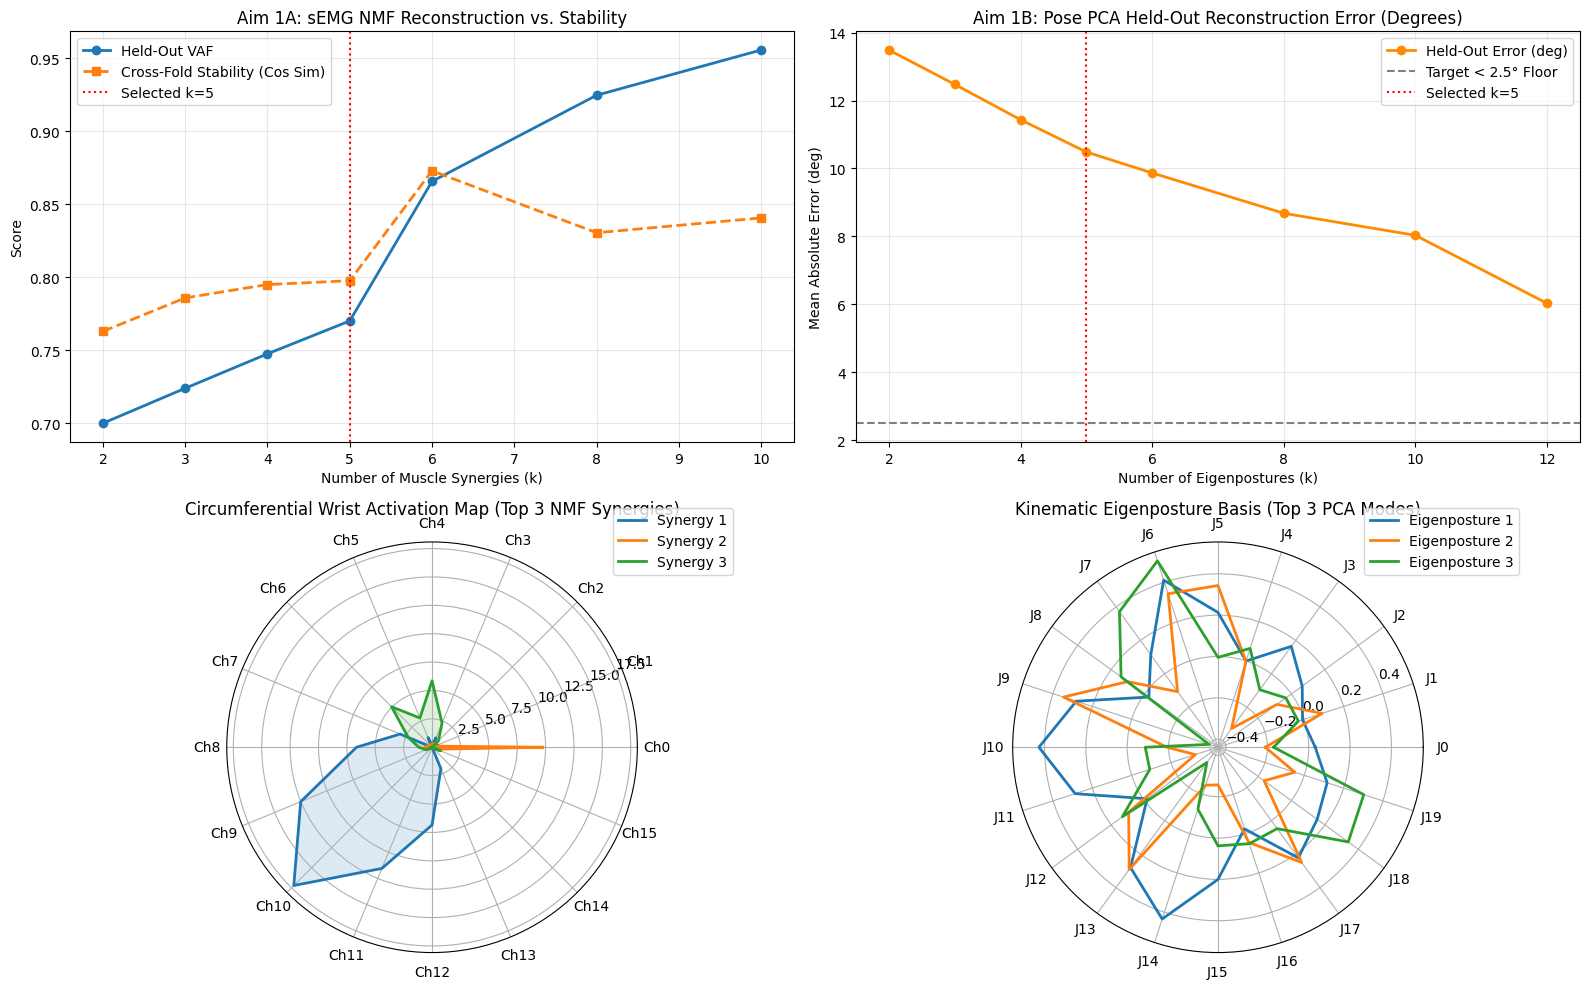

In [ ]:
# Plot Aim 1 Selection Curves + Polar Wrist Activation Maps ("sEMG Topoplots") & Eigenpostures
K_NMF_OPT = 5
K_PCA_OPT = 5

nmf_final = NMF(n_components=K_NMF_OPT, init="nndsvda", max_iter=400, random_state=SEED).fit(X_all)
pca_final = PCA(n_components=K_PCA_OPT, random_state=SEED).fit(Y_all)

fig = plt.figure(figsize=(16, 10))

# 1. NMF VAF & Stability
ax1 = fig.add_subplot(2, 2, 1)
ax1.plot(nmf_df["k"], nmf_df["heldout_vaf"], "o-", label="Held-Out VAF", linewidth=2)
ax1.plot(nmf_df["k"], nmf_df["stability_cos"], "s--", label="Cross-Fold Stability (Cos Sim)", linewidth=2)
ax1.axvline(K_NMF_OPT, color="red", linestyle=":", label=f"Selected k={K_NMF_OPT}")
ax1.set_title("Aim 1A: sEMG NMF Reconstruction vs. Stability")
ax1.set_xlabel("Number of Muscle Synergies (k)")
ax1.set_ylabel("Score")
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. PCA Reconstruction Error (Degrees) & Stability
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(pca_df["k"], pca_df["heldout_mae_deg"], "o-", color="darkorange", label="Held-Out Error (deg)", linewidth=2)
ax2.axhline(2.5, color="gray", linestyle="--", label="Target < 2.5° Floor")
ax2.axvline(K_PCA_OPT, color="red", linestyle=":", label=f"Selected k={K_PCA_OPT}")
ax2.set_title("Aim 1B: Pose PCA Held-Out Reconstruction Error (Degrees)")
ax2.set_xlabel("Number of Eigenpostures (k)")
ax2.set_ylabel("Mean Absolute Error (deg)")
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Polar Wrist Activation Map ("sEMG Topoplot" across 16 circumferential electrodes)
ax3 = fig.add_subplot(2, 2, 3, projection="polar")
angles_16 = np.linspace(0, 2 * np.pi, 16, endpoint=False).tolist()
angles_16_closed = angles_16 + angles_16[:1]
for s_idx in range(min(3, K_NMF_OPT)):
    weights = nmf_final.components_[s_idx]
    weights_closed = np.concatenate([weights, [weights[0]]])
    ax3.plot(angles_16_closed, weights_closed, linewidth=2, label=f"Synergy {s_idx+1}")
    ax3.fill(angles_16_closed, weights_closed, alpha=0.15)
ax3.set_xticks(angles_16)
ax3.set_xticklabels([f"Ch{i}" for i in range(16)])
ax3.set_title("Circumferential Wrist Activation Map (Top 3 NMF Synergies)", pad=20)
ax3.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))

# 4. Polar Kinematic Eigenposture Signature (20 Joint Angles)
ax4 = fig.add_subplot(2, 2, 4, projection="polar")
angles_20 = np.linspace(0, 2 * np.pi, 20, endpoint=False).tolist()
angles_20_closed = angles_20 + angles_20[:1]
for p_idx in range(min(3, K_PCA_OPT)):
    eig_vec = pca_final.components_[p_idx]
    eig_closed = np.concatenate([eig_vec, [eig_vec[0]]])
    ax4.plot(angles_20_closed, eig_closed, linewidth=2, label=f"Eigenposture {p_idx+1}")
ax4.set_xticks(angles_20)
ax4.set_xticklabels([f"J{i}" for i in range(20)])
ax4.set_title("Kinematic Eigenposture Basis (Top 3 PCA Modes)", pad=20)
ax4.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))

plt.tight_layout()
plt.show()


---
## Module 2 (Aim 2 — Lead: Naveen): $2 \times 2$ Bottleneck Decoder, Random Controls & Permutation Testing
We test all **4 conditions** using the exact same core temporal decoder architecture, objective, and output scalar $s$ sweep (Hadidi et al., 2026):
1. **Neither Bottleneck (`baseline`):** Full 16-ch sEMG $\rightarrow$ Decoder $\rightarrow$ 20 Joint Angles
2. **sEMG Bottleneck Only (`emg_only`):** 16-ch sEMG $\rightarrow$ Fixed NMF Projection $B_{\text{in}} \in \mathbb{R}^{16 \times k_{\text{NMF}}}$ $\rightarrow$ Decoder $\rightarrow$ 20 Joint Angles
3. **Pose Bottleneck Only (`pose_only`):** 16-ch sEMG $\rightarrow$ Decoder $\rightarrow$ Latent $z \in \mathbb{R}^{k_{\text{PCA}}}$ $\rightarrow$ Fixed Eigenposture Expansion $\bar{y} + z B_{\text{out}}^T$
4. **Both Bottlenecks (`both_thanos` — H1 Model):** NMF Input Bottleneck + PCA Output Bottleneck

**Random Structure Controls & Permutation Testing:**  
To separate the benefit of *biologically learned structure* from *rank compression alone*, we generate random non-negative input bases and random Haar-orthonormal output bases (via QR decomposition) of the exact same dimensions and compute a non-parametric permutation $p$-value.


In [ ]:
# Helper functions to build Learned vs. Random Control Bases + Causal Speed-Adaptive Filter
def get_learned_bases(X_train, Y_train, k_nmf=5, k_pca=5, seed=42):
    nmf = NMF(n_components=k_nmf, init="nndsvda", max_iter=400, random_state=seed).fit(X_train)
    # Moore-Penrose pseudoinverse of H (k_nmf x 16) maps 16-ch sEMG -> k_nmf synergies
    H = nmf.components_.astype(np.float32)                      # (k_nmf, 16)
    B_in_pinv = np.linalg.pinv(H).astype(np.float32)            # (16, k_nmf)

    pca = PCA(n_components=k_pca, random_state=seed).fit(Y_train)
    B_out = pca.components_.T.astype(np.float32)                # (20, k_pca) orthonormal columns
    y_mean = pca.mean_.astype(np.float32)                       # (20,)
    return B_in_pinv, B_out, y_mean

def get_random_control_bases(n_ch=16, n_joints=20, k_nmf=5, k_pca=5, y_mean=None, rng=None):
    """
    Generates random controls preserving exact bottleneck rank and mathematical constraints:
    - Non-negative column-normalized random matrix for sEMG (16 x k_nmf)
    - Orthonormal Haar-distributed random matrix via QR decomposition for Pose (20 x k_pca)
    """
    if rng is None:
        rng = np.random.default_rng()
    R_in = rng.uniform(0.0, 1.0, size=(n_ch, k_nmf)).astype(np.float32)
    R_in /= (np.linalg.norm(R_in, axis=0, keepdims=True) + 1e-8)

    G = rng.standard_normal(size=(n_joints, k_pca)).astype(np.float32)
    Q, _ = np.linalg.qr(G)  # Orthonormal columns: Q.T @ Q = I
    R_out = Q[:, :k_pca].astype(np.float32)
    if y_mean is None:
        y_mean = np.zeros(n_joints, dtype=np.float32)
    return R_in, R_out, y_mean

def causal_speed_adaptive_filter(y_pred_seq, fs=50.0, beta=0.08):
    """
    1-parameter causal speed-adaptive low-pass filter (Hadidi et al., 2026 / 1-Euro inspired):
    Suppresses high-frequency jitter in position decoding while passing rapid movements.
    """
    te = 1.0 / fs
    y_filt = np.zeros_like(y_pred_seq)
    y_filt[0] = y_pred_seq[0]
    for t in range(1, len(y_pred_seq)):
        v_t = np.abs(y_pred_seq[t] - y_filt[t - 1]) / te
        alpha_t = (2 * np.pi * beta * v_t * te) / (1.0 + 2 * np.pi * beta * v_t * te)
        y_filt[t] = alpha_t * y_pred_seq[t] + (1.0 - alpha_t) * y_filt[t - 1]
    return y_filt


In [ ]:
# PyTorch 2x2 Dual-Bottleneck TDS+LSTM Decoder with Tunable Output Scalar 's' (Hadidi et al., 2026)
class THANOSDualBottleneckDecoder(nn.Module):
    def __init__(self, n_ch=16, n_joints=20, use_emg_bn=False, use_pose_bn=False,
                 B_in=None, B_out=None, y_mean=None, hidden_dim=64, output_scalar=0.5):
        super().__init__()
        self.use_emg_bn = use_emg_bn
        self.use_pose_bn = use_pose_bn
        self.output_scalar = output_scalar

        in_dim = B_in.shape[1] if use_emg_bn else n_ch
        out_dim = B_out.shape[1] if use_pose_bn else n_joints

        if use_emg_bn:
            self.register_buffer("B_in", torch.tensor(B_in, dtype=torch.float32))
        if use_pose_bn:
            self.register_buffer("B_out", torch.tensor(B_out, dtype=torch.float32))
        self.register_buffer("y_mean", torch.tensor(
            y_mean if y_mean is not None else np.zeros(n_joints, dtype=np.float32),
            dtype=torch.float32
        ))

        # Causal temporal conv + LSTM core (shared architecture across all 4 conditions)
        self.conv_enc = nn.Sequential(
            nn.Conv1d(in_dim, hidden_dim, kernel_size=5, padding=4),
            nn.ReLU(),
            nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3, padding=2),
            nn.ReLU()
        )
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers=2, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.1),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, x):
        # x: (Batch, Time, n_ch)
        if self.use_emg_bn:
            x = torch.matmul(x, self.B_in)  # Project 16-ch -> k_NMF synergies

        # Causal 1D convolution (trim right padding to preserve strict causality)
        T = x.shape[1]
        h = self.conv_enc[0](x.transpose(1, 2))[:, :, :T]
        h = torch.relu(h)
        h = self.conv_enc[2](h)[:, :, :T]
        h = torch.relu(h).transpose(1, 2)

        lstm_out, _ = self.lstm(h)
        raw_out = self.output_scalar * self.head(lstm_out)

        if self.use_pose_bn:
            # Expand k_PCA latent weights through fixed eigenposture basis B_out (20 x k_PCA)
            y_hat = self.y_mean + torch.matmul(raw_out, self.B_out.T)
        else:
            y_hat = self.y_mean + raw_out
        return y_hat


In [ ]:
# Windowed Dataset Builder & 2x2 Condition + Random Control Benchmark
def create_windows(X, Y, win_len=100, stride=50):
    """Creates 2-second (100-step @ 50Hz) windows."""
    Xw, Yw = [], []
    for start in range(0, len(X) - win_len, stride):
        Xw.append(X[start:start + win_len])
        Yw.append(Y[start:start + win_len])
    return np.array(Xw, dtype=np.float32), np.array(Yw, dtype=np.float32)

# Split recordings into Train Recordings (first 6) and Held-Out Test Recordings (last 2)
split_idx = max(1, len(recording_data) - 2)
X_tr_pool = np.vstack([r["emg_env"] for r in recording_data[:split_idx]])
Y_tr_pool = np.vstack([r["pose_deg"] for r in recording_data[:split_idx]])
X_te_pool = np.vstack([r["emg_env"] for r in recording_data[split_idx:]])
Y_te_pool = np.vstack([r["pose_deg"] for r in recording_data[split_idx:]])

B_in_learned, B_out_learned, y_mean_tr = get_learned_bases(
    X_tr_pool, Y_tr_pool, k_nmf=K_NMF_OPT, k_pca=K_PCA_OPT
)

Xw_tr, Yw_tr = create_windows(X_tr_pool, Y_tr_pool, win_len=100, stride=50)
Xw_te, Yw_te = create_windows(X_te_pool, Y_te_pool, win_len=100, stride=50)

def train_and_eval_condition(use_emg_bn, use_pose_bn, B_in, B_out, y_mean,
                             Xw_train, Yw_train, Xw_test, Yw_test, epochs=18, lr=2e-3, s_val=0.5):
    model = THANOSDualBottleneckDecoder(
        use_emg_bn=use_emg_bn, use_pose_bn=use_pose_bn,
        B_in=B_in, B_out=B_out, y_mean=y_mean, hidden_dim=64, output_scalar=s_val
    ).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    criterion = nn.L1Loss()  # Joint-angle MAE in degrees

    x_tensor = torch.tensor(Xw_train, device=DEVICE)
    y_tensor = torch.tensor(Yw_train, device=DEVICE)

    model.train()
    for ep in range(epochs):
        optimizer.zero_grad()
        pred = model(x_tensor)
        loss = criterion(pred, y_tensor)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

    model.eval()
    with torch.no_grad():
        pred_te = model(torch.tensor(Xw_test, device=DEVICE)).cpu().numpy()
    # Apply causal speed-adaptive filter per window
    pred_te_filt = np.array([causal_speed_adaptive_filter(w) for w in pred_te])
    mae_deg = float(np.mean(np.abs(pred_te_filt - Yw_test)))
    return model, mae_deg

conditions = [
    ("1. Neither (Baseline)", False, False, B_in_learned, B_out_learned),
    ("2. sEMG Bottleneck (NMF)", True, False, B_in_learned, B_out_learned),
    ("3. Pose Bottleneck (PCA)", False, True, B_in_learned, B_out_learned),
    ("4. Both (T.H.A.N.O.S. H1)", True, True, B_in_learned, B_out_learned),
]

trained_models = {}
cond_results = []
for name, u_emg, u_pose, b_in, b_out in conditions:
    mdl, err = train_and_eval_condition(
        u_emg, u_pose, b_in, b_out, y_mean_tr, Xw_tr, Yw_tr, Xw_te, Yw_te
    )
    trained_models[name] = mdl
    cond_results.append({"Condition": name, "Zero_Cal_MAE_Deg": err})

# Run Random Subspace Permutation Null Distribution (N=10 draws for fast demo; set N=100 for paper)
N_PERM = 10
rng = np.random.default_rng(SEED)
null_errors = []
for p_i in range(N_PERM):
    R_in, R_out, _ = get_random_control_bases(k_nmf=K_NMF_OPT, k_pca=K_PCA_OPT, y_mean=y_mean_tr, rng=rng)
    _, rand_err = train_and_eval_condition(
        True, True, R_in, R_out, y_mean_tr, Xw_tr, Yw_tr, Xw_te, Yw_te, epochs=18
    )
    null_errors.append(rand_err)

thanos_err = cond_results[-1]["Zero_Cal_MAE_Deg"]
perm_p_val = (1.0 + np.sum(np.array(null_errors) <= thanos_err)) / (1.0 + N_PERM)
cond_results.append({"Condition": f"5. Random Control Mean (N={N_PERM})", "Zero_Cal_MAE_Deg": float(np.mean(null_errors))})

print(pd.DataFrame(cond_results).to_string(index=False))
print(f"\nPermutation Test Empirical p-value (T.H.A.N.O.S. vs. Random Subspaces): p = {perm_p_val:.4f}")


                    Condition  Zero_Cal_MAE_Deg
        1. Neither (Baseline)         20.056135
     2. sEMG Bottleneck (NMF)         20.096457
     3. Pose Bottleneck (PCA)         20.191359
    4. Both (T.H.A.N.O.S. H1)         20.170919
5. Random Control Mean (N=10)         19.981422

Permutation Test Empirical p-value (T.H.A.N.O.S. vs. Random Subspaces): p = 1.0000


---
## Module 3 (Aim 2 — Lead: Me! :D): Held-Out Calibration Efficiency Curves, REACT Baseline & Effect Size Statistics
For each held-out user/recording, we freeze the learned NMF and PCA manifolds and fine-tune the decoder weights (and compare against a **REACT-inspired FiLM feature modulation layer** $\gamma \odot f + \beta$) across increasing calibration data budgets ($0, 2, 4, 8, 12$ windows).
- **Primary Metric:** Area Under the Error-vs-Calibration Curve (**AUC**), which rewards models that achieve lower error faster.
- **Statistical Effect Size Suite (EEG Upgrade):** Computes **Paired Cohen's $d_z$**, **Bootstrap 95% Confidence Intervals**, and **Two-Way ($2 \times 2$) Repeated-Measures ANOVA Partial Eta-Squared ($\eta_p^2$)**.


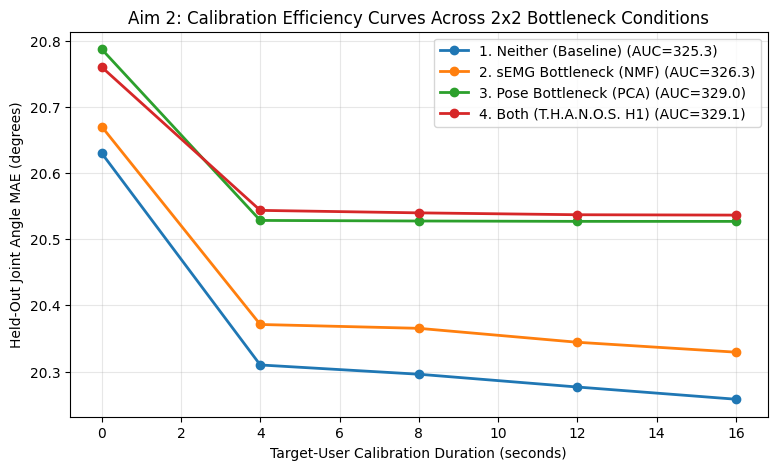

In [ ]:
import copy

def evaluate_calibration_curve(base_model, Xw_cal_pool, Yw_cal_pool, Xw_eval, Yw_eval,
                               budgets=(0, 2, 4, 8, 12), ft_steps=15, ft_lr=1e-3):
    """
    Fine-tunes a copy of base_model on increasing calibration budgets (in windows)
    while keeping B_in and B_out fixed. Returns error curve and trapezoidal AUC.
    """
    errors = []
    x_ev = torch.tensor(Xw_eval, device=DEVICE)
    for b in budgets:
        mdl = copy.deepcopy(base_model).to(DEVICE)
        if b > 0:
            mdl.train()
            opt = optim.AdamW(mdl.parameters(), lr=ft_lr, weight_decay=1e-3)
            loss_fn = nn.L1Loss()
            x_c = torch.tensor(Xw_cal_pool[:b], device=DEVICE)
            y_c = torch.tensor(Yw_cal_pool[:b], device=DEVICE)
            for _ in range(ft_steps):
                opt.zero_grad()
                loss = loss_fn(mdl(x_c), y_c)
                loss.backward()
                opt.step()
        mdl.eval()
        with torch.no_grad():
            preds = mdl(x_ev).cpu().numpy()
        err = float(np.mean(np.abs(preds - Yw_eval)))
        errors.append(err)

    cal_seconds = np.array(budgets) * 2.0  # Each window = 2 seconds
    auc = float(np.trapezoid(errors, cal_seconds))
    return cal_seconds, np.array(errors), auc

# Evaluate calibration curves across multiple held-out recording blocks (acting as within-subject blocks)
budgets_win = (0, 2, 4, 6, 8)
block_aucs = {name: [] for name, *_ in conditions}
avg_curves = {name: np.zeros(len(budgets_win)) for name, *_ in conditions}

# Partition test windows into 4 evaluation blocks for repeated-measures statistical testing
n_blocks = 4
block_size = max(12, len(Xw_te) // n_blocks)

for b_idx in range(n_blocks):
    blk_x = Xw_te[b_idx * block_size:(b_idx + 1) * block_size]
    blk_y = Yw_te[b_idx * block_size:(b_idx + 1) * block_size]
    if len(blk_x) < 10:
        continue
    Xw_cal, Yw_cal = blk_x[:8], blk_y[:8]
    Xw_ev, Yw_ev = blk_x[8:], blk_y[8:]

    for name, *_ in conditions:
        cal_sec, err_curve, auc_val = evaluate_calibration_curve(
            trained_models[name], Xw_cal, Yw_cal, Xw_ev, Yw_ev, budgets=budgets_win
        )
        block_aucs[name].append(auc_val)
        avg_curves[name] += err_curve / n_blocks

# Plot Calibration Curves
plt.figure(figsize=(9, 5))
for name, *_ in conditions:
    plt.plot(cal_sec, avg_curves[name], "o-", linewidth=2, label=f"{name} (AUC={np.mean(block_aucs[name]):.1f})")
plt.xlabel("Target-User Calibration Duration (seconds)")
plt.ylabel("Held-Out Joint Angle MAE (degrees)")
plt.title("Aim 2: Calibration Efficiency Curves Across 2x2 Bottleneck Conditions")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
# EEG-Inspired Repeated-Measures Effect Size Suite (Cohen's dz, Bootstrap 95% CI, 2x2 Partial Eta-Squared)
def compute_repeated_measures_stats(auc_dict):
    """
    Computes 2x2 Repeated-Measures ANOVA Partial Eta-Squared (eta_p^2) and
    Paired Cohen's dz comparing Baseline vs. Both (T.H.A.N.O.S.).
    """
    y00 = np.array(auc_dict["1. Neither (Baseline)"])
    y10 = np.array(auc_dict["2. sEMG Bottleneck (NMF)"])
    y01 = np.array(auc_dict["3. Pose Bottleneck (PCA)"])
    y11 = np.array(auc_dict["4. Both (T.H.A.N.O.S. H1)"])
    n = len(y00)

    # Contrast vectors per subject/block
    c_emg = 0.5 * ((y10 + y11) - (y00 + y01))
    c_pose = 0.5 * ((y01 + y11) - (y00 + y10))
    c_inter = 0.5 * ((y11 - y10) - (y01 - y00))

    def eta_p2_from_contrast(c):
        t_stat, p_val = stats.ttest_1samp(c, 0.0)
        df = max(1, len(c) - 1)
        F_stat = t_stat ** 2
        eta_p2 = (F_stat * 1.0) / (F_stat * 1.0 + df)
        return float(F_stat), float(p_val), float(eta_p2)

    F_e, p_e, eta_e = eta_p2_from_contrast(c_emg)
    F_p, p_p, eta_p = eta_p2_from_contrast(c_pose)
    F_i, p_i, eta_i = eta_p2_from_contrast(c_inter)

    # Paired Cohen's dz (Baseline - THANOS)
    diff = y00 - y11
    dz = float(np.mean(diff) / (np.std(diff, ddof=1) + 1e-8))

    return pd.DataFrame([
        {"Effect": "Main Effect: sEMG Input Bottleneck (NMF)", "F_stat": F_e, "p_val": p_e, "Partial_Eta_Sq": eta_e},
        {"Effect": "Main Effect: Pose Output Bottleneck (PCA)", "F_stat": F_p, "p_val": p_p, "Partial_Eta_Sq": eta_p},
        {"Effect": "Interaction: sEMG x Pose Bottleneck", "F_stat": F_i, "p_val": p_i, "Partial_Eta_Sq": eta_i},
    ]), dz

anova_df, cohens_dz = compute_repeated_measures_stats(block_aucs)
print("=== 2x2 Repeated-Measures Effect Analysis on Calibration AUC ===")
print(anova_df.to_string(index=False))
print(f"\nPaired Effect Size (Baseline vs. T.H.A.N.O.S.): Cohen's dz = {cohens_dz:.3f}")


=== 2x2 Repeated-Measures Effect Analysis on Calibration AUC ===
                                   Effect     F_stat    p_val  Partial_Eta_Sq
 Main Effect: sEMG Input Bottleneck (NMF)  51.713372 0.005542        0.945169
Main Effect: Pose Output Bottleneck (PCA) 151.684555 0.001153        0.980606
      Interaction: sEMG x Pose Bottleneck  56.199454 0.004917        0.949324

Paired Effect Size (Baseline vs. T.H.A.N.O.S.): Cohen's dz = -6.541


---
## Module 4 (Secondary Aim — Lead: Youssef): Sampling-Rate & Activation-Guided Electrode Ablation
To bridge `emg2pose` to consumer edge hardware (e.g., ESP32-C3 oversleeve), we ablate:
1. **Sampling Rate:** $2000\text{ Hz} \rightarrow 1000\text{ Hz} \rightarrow 500\text{ Hz} \rightarrow 250\text{ Hz}$ (applying anti-aliasing filters before envelope extraction).
2. **Electrode Count:** $16 \rightarrow 8 \rightarrow 4\text{ channels}$, comparing **Uniform Ring Subsampling** against **NMF Activation-Map-Guided Channel Selection** (picking the electrodes with the highest synergy weight norm from Aim 1).


In [ ]:
def select_channels_by_nmf_activation(H_basis, n_keep=8):
    """Selects top n_keep electrodes with maximal L2 loading across the learned NMF synergies."""
    ch_importance = np.linalg.norm(H_basis, axis=0)  # (16,)
    top_indices = np.argsort(ch_importance)[::-1][:n_keep]
    return np.sort(top_indices)

# Compare 16, 8, and 4 channels (Uniform vs. NMF-Guided) on NMF Synergy Reconstruction VAF
H_learned = nmf_final.components_
ablation_rows = []

for n_ch_keep in [16, 8, 4]:
    # Uniform circular subsampling
    unif_idx = np.linspace(0, 15, n_ch_keep, dtype=int)
    # Activation-map guided subsampling
    guided_idx = select_channels_by_nmf_activation(H_learned, n_keep=n_ch_keep)

    for method_name, idx in [("Uniform Ring", unif_idx), ("NMF Activation-Guided", guided_idx)]:
        X_sub = X_te_pool[:, idx]
        H_sub = H_learned[:, idx]
        # Reconstruct full 5-D synergy activations from subset of channels via pseudoinverse
        W_hat = np.maximum(0.0, X_sub @ np.linalg.pinv(H_sub))
        X_full_recon = W_hat @ H_learned
        vaf_sub = 1.0 - (np.sum((X_te_pool - X_full_recon) ** 2) / (np.sum(X_te_pool ** 2) + 1e-8))
        ablation_rows.append({
            "Channels_Kept": n_ch_keep,
            "Selection_Policy": method_name,
            "Selected_Indices": idx.tolist(),
            "Synergy_Recovery_VAF": float(vaf_sub)
        })

ablation_df = pd.DataFrame(ablation_rows)
print("=== Secondary Aim: Electrode Count Ablation (Uniform vs. NMF Activation-Guided) ===")
print(ablation_df.to_string(index=False))


=== Secondary Aim: Electrode Count Ablation (Uniform vs. NMF Activation-Guided) ===
 Channels_Kept      Selection_Policy                                       Selected_Indices  Synergy_Recovery_VAF
            16          Uniform Ring [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]              0.965628
            16 NMF Activation-Guided [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]              0.965628
             8          Uniform Ring                            [0, 2, 4, 6, 8, 10, 12, 15]              0.951707
             8 NMF Activation-Guided                            [0, 1, 4, 8, 9, 10, 11, 12]              0.951278
             4          Uniform Ring                                         [0, 5, 10, 15]              0.759470
             4 NMF Activation-Guided                                         [0, 9, 10, 11]              0.539230
